# Binomial trees in SigAlg I: the basics

This is the first of three notebooks on risk-neutral valuation in SigAlg with binomial trees. The binomial model is the simplest nontrivial model of asset prices, and since every binomial tree out to a finite horizon is built from a finite sample space, SigAlg can represent it exactly.

Here we recall discrete-time stochastic processes and filtrations, specialize to the binomial model, and introduce its three generation modes (exhaustive enumeration, sparse representative enumeration, and Monte Carlo simulation), which let the same model scale from a handful of time steps to many. The second notebook treats contingent claims, and the third prices them.

The mathematics is described concisely. A textbook covering the same material at a more leisurely pace, such as Shreve's *Stochastic Calculus for Finance I: The Binomial Asset Pricing Model*, is a useful companion. At the bare minimum, the reader should be familiar with manipulating random variables and their (conditional) expected values.


In [1]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX rendering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## The binomial pricing model

### General stochastic processes

SigAlg models price trajectories of assets as *discrete-time stochastic processes*. Such an object is a collection of random variables $S_t$ (indexed over $t\in \{0,1,\ldots,T\}$) on a fixed probability space $(\Omega, \mathcal{F},P)$. For each sample point $\omega\in \Omega$, we have a sequence of real numbers
$$
(S_0(\omega), S_1(\omega),\ldots,S_T(\omega))\in \mathbb{R}^{T+1},
$$
which is understood as a potential price trajectory of the asset. As the sample point $\omega \in \Omega$ varies, we get different price trajectories, and a price trajectory $(s_0,s_1,\ldots,s_T)\in \mathbb{R}^{T+1}$ has a probability of being observed determined by the probability measure:
$$
P(S_0 = s_0, S_1=s_1,\ldots,S_T=s_T).
$$
The object $\mathcal{F}$ is the *$\sigma$-algebra* of the probability space (the namesake of SigAlg) which, in a sense, encodes the "total information" at hand. It is equipped with a *filtration* induced by the stochastic process, which is a sequence of sub-$\sigma$-algebras terminating with $\mathcal{F}$ itself:
$$
\mathcal{F}_0 \subset \mathcal{F}_1 \subset \cdots \subset \mathcal{F}_T = \mathcal{F}.
$$
The $t$-th $\sigma$-algebra in this filtration is the one generated by the stochastic process up to time $t$:
$$
\mathcal{F}_t = \sigma(S_0,S_1,\ldots,S_t).
$$
The reader unfamiliar with measure-theoretic probability theory should understand $\mathcal{F}_t$ as a partition of the sample space (assuming the sample space is finite, which it always is in SigAlg): Two sample points $\omega$ and $\omega'$ are in the same $\mathcal{F}_t$-component of $\Omega$ if and only if their length-$t$ partial trajectories are equal:
$$
(S_0(\omega),S_1(\omega),\ldots,S_t(\omega)) = (S_0(\omega'),S_1(\omega'),\ldots,S_t(\omega')).
$$
We will also deal with *$\mathcal{F}_t$-measurable random variables*. These are just random variables $X$ on $(\Omega, \mathcal{F}, P)$ that are constant on the $\mathcal{F}_t$-components.

### The definition of a binomial model

A *binomial model* is discrete-time stochastic process $S_t$ that models asset prices with particularly simple dynamics. At any given instant of time $t$, the current price $S_t(\omega)$ may either move up by a factor of $u$, or down by a factor of $d$ (we assume $0< d < 1 < u$), so that either $S_{t+1}(\omega) = uS_t(\omega)$ or $S_{t+1}(\omega) = dS_t(\omega)$. We assume the up-move occurs with probability $p_u$, the down-move with probability $p_d=1-p_u$, and that the price moves are independent over time. We also assume that the initial price $S_0$ is deterministic. The range of the random variable $S_t$ is the set
$$
\{S_0 u^{n}d^{t-n} : n=0,1,\ldots,t\},
$$
and the distribution of $S_t$ is given by
$$
P \left( S_t = S_0u^{n}d^{t-n}\right) = \binom{t}{n}p_u^np_d^{t-n},
$$
for each $n=0,1,\ldots,t$. The probability measure $P$ is called the *real-world measure*, to distinguish it from another probability measure that will come later.

In the following code block, we implement a binomial model in SigAlg with the following parameters:

$$
S_0 = 100, \quad u = 1.1, \quad d = 0.9, \quad p_u = 0.7, \quad R = 1.05, \quad T = 3.
$$

The parameter $R$ is the per-period *risk-free gross return*, which is used for pricing in the third notebook of this series.

In [2]:
import sigalg as sa

S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)
print(S)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9


Note that the default sample space generated by SigAlg is the set of integers $\Omega=\{0,1,\ldots,7\}$. For each $\omega\in \Omega$, the corresponding row of the printout gives the price trajectory
$$
(S_0(\omega), S_1(\omega), S_2(\omega), S_3(\omega)).
$$
There are exactly $2^T = 2^3 =8$ distinct price trajectories. We may plot them through the `plot_trajectories` method of the model.

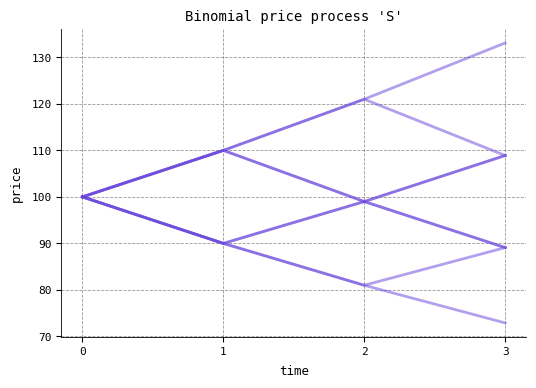

In [3]:
import matplotlib.pyplot as plt

sa.style.use_globally()

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(ax=ax, plot_kwargs={"alpha": 0.5})
plt.show()

The real-world probability measure $P$ is accessible via an appropriate attribute of the model.

In [4]:
P = S.prob_measure
print(P)

Probability measure 'P':
           P
omega       
0      0.343
1      0.147
2      0.147
3      0.063
4      0.147
5      0.063
6      0.063
7      0.027


We may push this measure forward through the random variable $S_3$ to get the probability distribution of the four distinct terminal asset prices. This uses the `>>` operator for pushforwards.

In [5]:
print(P >> S[3])

Probability measure 'P_S_3':
       P_S_3
S_3         
72.9   0.027
89.1   0.189
108.9  0.441
133.1  0.343


Note that these probabilities match the binomial distribution with parameter $p$:

In [6]:
p_d = 1 - p_u
p_d**3, 3 * p_u * p_d**2, 3 * p_u**2 * p_d, p_u**3

(0.027000000000000014, 0.18900000000000003, 0.441, 0.3429999999999999)

### Generation modes

For the binomial model above with $T=3$, there are eight distinct price trajectories, but only four terminal prices. Instead of exhaustively enumerating all $2^T$ price trajectories, sometimes it is convenient to generate a smaller representative collection of $T+1$ trajectories. This may be accomplished by setting the parameter `enum_mode="sparse"` in the call to `generate`.

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0   90.0   99.0  108.9
2      100.0   90.0   81.0   89.1
3      100.0   90.0   81.0   72.9


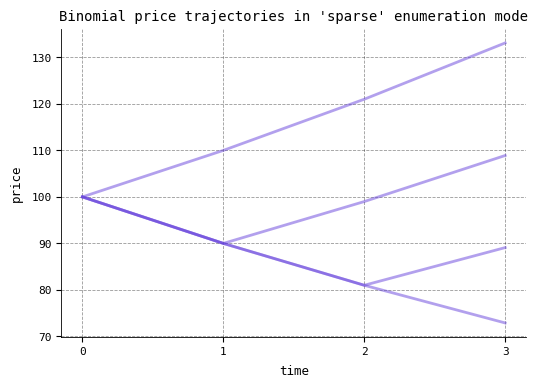

In [7]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    enum_mode="sparse",
    mode="enum",
    length=T,
    name="S",
)
print(S)

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(
    ax=ax,
    title="Binomial price trajectories in 'sparse' enumeration mode",
    plot_kwargs={"alpha": 0.5},
)
plt.show()

The representative price trajectories in `sparse` mode are those that do not mix up- and down-moves: All the down-moves are performed first, then all the up-moves.

In addition to sparse enumeration, SigAlg also supports Monte Carlo simulation by setting `mode="sim"`, and specifying the number of trajectories to simulate. We demonstrate this in the next code cell with a new set of parameters and a longer time horizon of $T=100$.

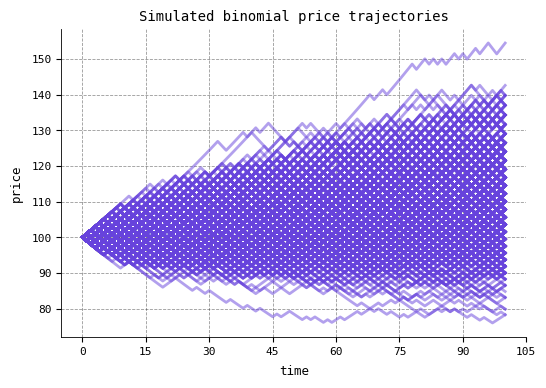

In [8]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=1.01,
    down_factor=0.99,
    up_prob=0.55,
    risk_free_gross_return=1.005,
    mode="sim",
    n_trajectories=1_000,
    length=100,
    name="S",
)

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(
    ax=ax,
    title="Simulated binomial price trajectories",
    plot_kwargs={"alpha": 0.5},
)
plt.show()